# Static Training Run Energy Simulator
Predict cumulative energy consumption over wall time for static TP/PP strategies using calibration data from `profile_strategies.py`.


## Regenerate Paper Rollout Plot With Custom Font

This cell rebuilds the exact `324.21h` carbon-aware scheduling plot from the saved May 20B run. It reads `results.csv`, replays the stored policy strategy sequences through the simulator, scales the carbon plot to kgCO2, and uses both color and line/marker patterns so the policies remain distinguishable in black-and-white print. By default it leaves the font family unset so Matplotlib uses the same configured default as the rest of the notebook.


,label,saved_carbon_g,replay_carbon_g,saved_wall_h,replay_wall_h,saved_reshards,replay_reshards,carbon_delta_g,wall_delta_h
0,"Best Static = static(1,1)",14775.1,14775.1,50.87,50.87,0,0,-0.0,0.0
1,Greedy,14098.2,14098.2,58.96,58.96,9,9,0.0,0.0
2,Job Shifting (wait=48.0h),11773.7,11773.7,50.87,50.87,0,0,0.0,0.0
3,Fixed Start Time Dynamic Parallelism,13597.2,13597.2,61.59,61.59,7,7,0.0,0.0
4,Job Shifting + Dynamic Parallelism (wait=48.0h),10921.2,10921.2,61.58,61.58,7,7,0.0,-0.0


Using Matplotlib default font family: ['sans-serif']
Saved PNG: runs/may_20b_deadline120_shift48_q50m_superadd/rollout_offset_324.2h_matplotlib_default_kgco2_paper_ready_equal_gaps.png
Saved PDF: runs/may_20b_deadline120_shift48_q50m_superadd/rollout_offset_324.2h_matplotlib_default_kgco2_paper_ready_equal_gaps.pdf


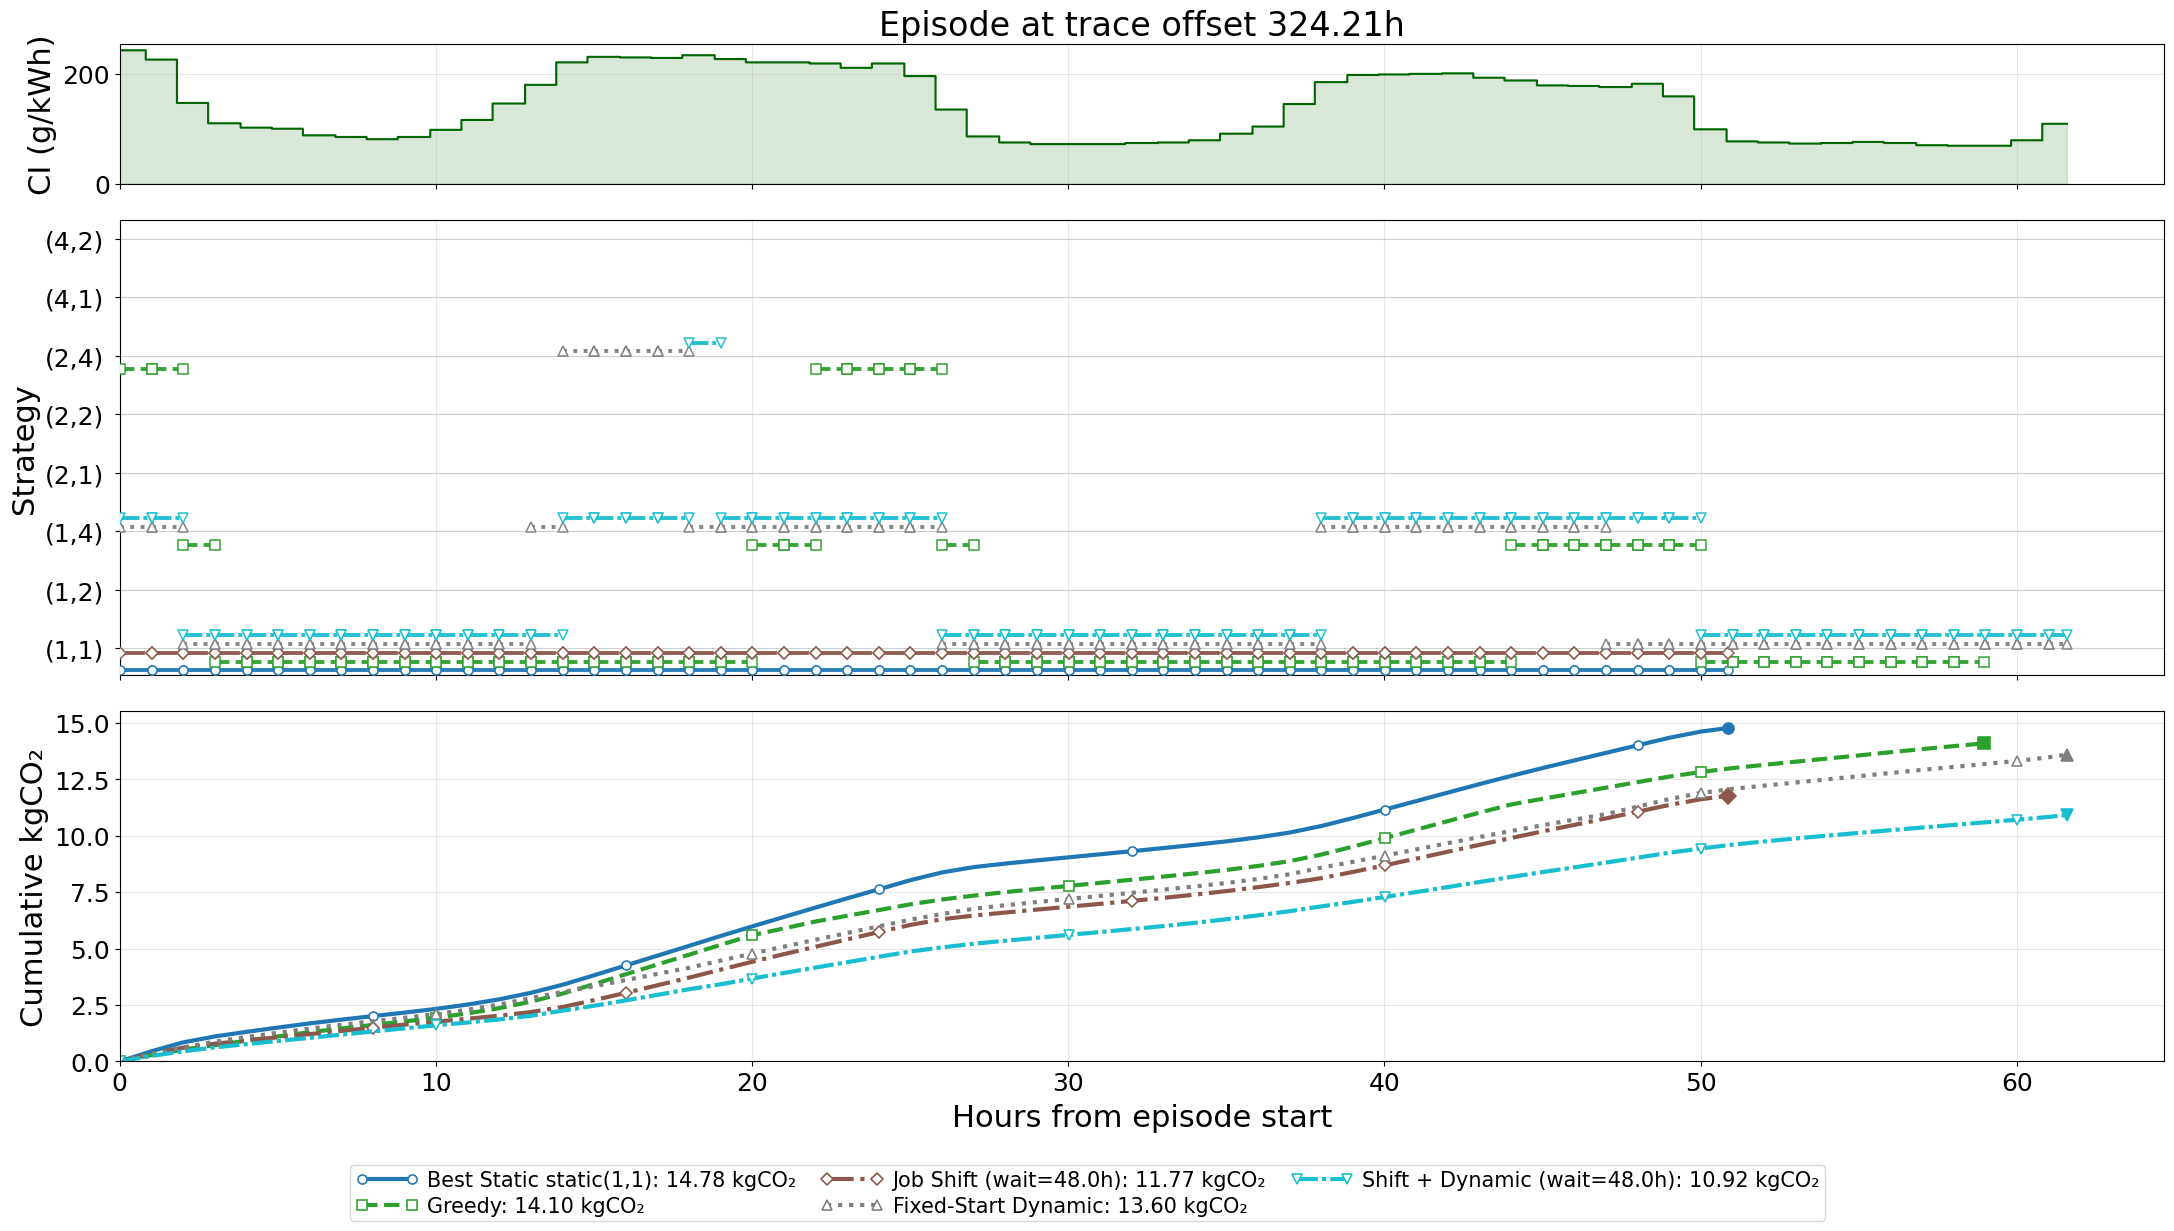

In [16]:
from pathlib import Path
import json
import os
import re
import sys

os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj)


# =====================================================================
# Plot styling
# =====================================================================
PLOT_FONT_FAMILY = None  # Use Matplotlib's configured default font family
PLOT_BASE_FONT_SIZE = 18
PLOT_TITLE_SIZE = 24
PLOT_LABEL_SIZE = 22
PLOT_TICK_SIZE = 18
PLOT_LEGEND_SIZE = 15
PLOT_DPI = 300

# Big canvas for readability. This is intentionally large because the figure
# uses paper/presentation-style fonts and three stacked panels.
PLOT_FIGSIZE = (21.75, 14.0)

# Manual layout controls. We use set_position() below instead of tight_layout()
# so the top CI plot and middle strategy plot get enough height and width.
PLOT_LEFT_MARGIN = 0.055
PLOT_RIGHT_MARGIN = 0.995

# =====================================================================
# Middle strategy panel controls
# =====================================================================
PLOT_STRATEGY_LINE_WIDTH = 2.8

# Strategy-band rule:
# Strategy labels are categorical. Each strategy row owns the vertical band
# immediately below it. A point between two neighboring strategy labels is
# assigned to the upper-bounding strategy.
#
# To avoid visual interference between neighboring rows, we expand the
# displayed distance between categorical strategy rows using ROW_GAP, then
# apply a small downward-only dodge inside the upper part of each band.
PLOT_STRATEGY_ROW_GAP = 2.00
PLOT_STRATEGY_Y_PAD = 0.65
PLOT_STRATEGY_DODGE = 0.26
PLOT_STRATEGY_TOP_INSET = 0.035
PLOT_STRATEGY_ALPHA = 0.95
PLOT_STRATEGY_SHOW_BAND_BOUNDARIES = True

# =====================================================================
# Legend/layout controls
# =====================================================================
PLOT_LEGEND_Y = 0.066
PLOT_LEGEND_NCOL = 3

# Equal vertical spacing between the three plot panels.
PANEL_GAP = 0.026

# Panel heights. The strategy panel gets the most space because it carries
# categorical schedule information.
CI_PANEL_HEIGHT = 0.100
STRATEGY_PANEL_HEIGHT = 0.325
CARBON_PANEL_HEIGHT = 0.250

# Keep enough bottom room for x-label + legend, but not too much.
CARBON_PANEL_BOTTOM = 0.180

# =====================================================================
# Units / output naming
# =====================================================================
CARBON_SCALE = 1000.0
CARBON_UNIT = "kgCO₂"
OUTPUT_SUFFIX = "matplotlib_default_kgco2_paper_ready_equal_gaps"

# Exact episode behind runs/.../rollout_offset_324.2h_paper_largefont.png
PAPER_OFFSET_H = 324.21349884662027
RUN_REL = Path("runs/may_20b_deadline120_shift48_q50m_superadd")
TRACE_REL = Path("data/carbon_2024_05_hourly.csv")

TOKENS = 20_000_000_000
MAX_EPISODE_HOURS = 120.0


# =====================================================================
# Repo / data loading
# =====================================================================
def find_repo_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "evaluate_carbon_policy.py").exists():
            return candidate
    raise FileNotFoundError("Could not find evaluate_carbon_policy.py above cwd")


REPO_ROOT = find_repo_root(Path.cwd().resolve())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from evaluate_carbon_policy import (  # noqa: E402
    BEST_CASE_SWITCHING_LABEL,
    GREEDY_LABEL,
    JOB_SHIFT_LABEL,
    ORACLE_SHIFT_SWITCH_LABEL,
    _fastest_strategy_idx,
    _replay_action_sequence,
    default_config,
    load_carbon_trace,
    plot_comparison,
    rollout_static,
)

run_dir = REPO_ROOT / RUN_REL
trace_path = REPO_ROOT / TRACE_REL
results_path = run_dir / "results.csv"

trace_t, trace_ci, _ = load_carbon_trace(str(trace_path))

cfg = default_config(
    pretraining_tokens=TOKENS,
    global_batch_size=16,
    seq_length=1024,
    n_gpus=8,
    model_num_params=None,
    model_name=None,
    filter_strategies=False,
    gpu_memory_gb=48.0,
    usable_memory_frac=0.90,
    bytes_per_param_training=18.0,
    activation_reserve_gb=4.0,
    min_pp=1,
    verbose_feasibility=False,
)

results = pd.read_csv(results_path)
episode_rows = results.loc[(results["offset_h"] - PAPER_OFFSET_H).abs() < 1e-6].copy()

if episode_rows.empty:
    nearest_idx = (results["offset_h"] - PAPER_OFFSET_H).abs().idxmin()
    nearest = results.loc[nearest_idx, "offset_h"]
    raise ValueError(f"No rows for offset {PAPER_OFFSET_H}; nearest offset is {nearest}")

static_rows = episode_rows.loc[
    episode_rows["policy"].str.startswith("static")
    & episode_rows["completed"].astype(bool)
]
best_static_policy = static_rows.sort_values("carbon_g").iloc[0]["policy"]

policy_rows = {
    row["policy"]: row
    for _, row in episode_rows.iterrows()
}


# =====================================================================
# Replay helpers
# =====================================================================
def parse_strategy_sequence(row: pd.Series) -> list[int]:
    sequence = row.get("strategy_sequence", "[]")
    if pd.isna(sequence):
        return []
    return [int(x) for x in json.loads(sequence)]


def replay_policy(row: pd.Series):
    sequence = parse_strategy_sequence(row)
    if not sequence:
        raise ValueError(f"No strategy sequence stored for {row['policy']}")

    start_offset_s = float(row["start_offset_h"]) * 3600.0
    max_hours = max(float(row["wall_h"]) + 2.0, 2.0)
    policy = row["policy"]

    if policy.startswith("static") or policy == JOB_SHIFT_LABEL:
        return rollout_static(
            cfg,
            trace_t,
            trace_ci,
            start_offset_s,
            strategy_idx=int(sequence[0]),
            max_hours=max_hours,
            wrap_trace=False,
        )

    initial_strategy_idx = None
    if policy == GREEDY_LABEL:
        initial_strategy_idx = _fastest_strategy_idx(cfg)

    return _replay_action_sequence(
        cfg,
        trace_t,
        trace_ci,
        start_offset_s,
        sequence,
        initial_strategy_idx=initial_strategy_idx,
        decision_interval_s=3600.0,
        max_hours=max_hours,
        wrap_trace=False,
    )


# =====================================================================
# Select policies to plot
# =====================================================================
plot_specs = [
    (f"Best Static = {best_static_policy}", policy_rows[best_static_policy]),
    (GREEDY_LABEL, policy_rows[GREEDY_LABEL]),
]

if JOB_SHIFT_LABEL in policy_rows:
    wait_h = float(policy_rows[JOB_SHIFT_LABEL]["wait_h"])
    plot_specs.append(
        (f"{JOB_SHIFT_LABEL} (wait={wait_h:.1f}h)", policy_rows[JOB_SHIFT_LABEL])
    )

if BEST_CASE_SWITCHING_LABEL in policy_rows:
    plot_specs.append(
        (BEST_CASE_SWITCHING_LABEL, policy_rows[BEST_CASE_SWITCHING_LABEL])
    )

if ORACLE_SHIFT_SWITCH_LABEL in policy_rows:
    wait_h = float(policy_rows[ORACLE_SHIFT_SWITCH_LABEL]["wait_h"])
    plot_specs.append(
        (
            f"{ORACLE_SHIFT_SWITCH_LABEL} (wait={wait_h:.1f}h)",
            policy_rows[ORACLE_SHIFT_SWITCH_LABEL],
        )
    )

rollouts_to_plot = {}
replay_checks = []

for label, row in plot_specs:
    sim = replay_policy(row)
    rollouts_to_plot[label] = sim

    replay_checks.append({
        "label": label,
        "saved_carbon_g": float(row["carbon_g"]),
        "replay_carbon_g": sim.total_carbon_g,
        "saved_wall_h": float(row["wall_h"]),
        "replay_wall_h": sim.cursor_s / 3600.0,
        "saved_reshards": int(row["reshards"]),
        "replay_reshards": int(sim.reshard_count),
    })

check_df = pd.DataFrame(replay_checks)
check_df["carbon_delta_g"] = check_df["replay_carbon_g"] - check_df["saved_carbon_g"]
check_df["wall_delta_h"] = check_df["replay_wall_h"] - check_df["saved_wall_h"]

display(check_df.round({
    "saved_carbon_g": 1,
    "replay_carbon_g": 1,
    "carbon_delta_g": 4,
    "saved_wall_h": 2,
    "replay_wall_h": 2,
    "wall_delta_h": 6,
}))

print(f"Using Matplotlib default font family: {plt.rcParams['font.family']}")


# =====================================================================
# Styles
# =====================================================================
POLICY_STYLES = [
    {"color": "#1f77b4", "linestyle": "-", "marker": "o"},
    {"color": "#2ca02c", "linestyle": "--", "marker": "s"},
    {"color": "#8c564b", "linestyle": "-.", "marker": "D"},
    {"color": "#7f7f7f", "linestyle": ":", "marker": "^"},
    {"color": "#17becf", "linestyle": (0, (5, 1, 1, 1)), "marker": "v"},
]

rc_params = {
    "font.size": PLOT_BASE_FONT_SIZE,
    "axes.titlesize": PLOT_TITLE_SIZE,
    "axes.labelsize": PLOT_LABEL_SIZE,
    "xtick.labelsize": PLOT_TICK_SIZE,
    "ytick.labelsize": PLOT_TICK_SIZE,
    "legend.fontsize": PLOT_LEGEND_SIZE,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}

if PLOT_FONT_FAMILY is not None:
    rc_params["font.family"] = PLOT_FONT_FAMILY
    print(f"Using custom font family: {PLOT_FONT_FAMILY}")


# =====================================================================
# Plot helper functions
# =====================================================================
def apply_policy_style_to_line(line, style, marker_every: int, marker_size: float):
    line.set_color(style["color"])
    line.set_linestyle(style["linestyle"])
    line.set_linewidth(PLOT_STRATEGY_LINE_WIDTH)
    line.set_marker(style["marker"])
    line.set_markevery(marker_every)
    line.set_markersize(marker_size)
    line.set_markerfacecolor("white")
    line.set_markeredgewidth(1.1)
    line.set_alpha(PLOT_STRATEGY_ALPHA)
    line.set_solid_capstyle("butt")
    line.set_zorder(3)


def scale_strategy_collections(ax_strategy):
    """Scale collection-based strategy segments, if any, to match row-gap y-axis."""
    for collection in ax_strategy.collections:
        try:
            segments = collection.get_segments()
            scaled_segments = []

            for seg in segments:
                seg = np.asarray(seg, dtype=float).copy()
                if seg.ndim == 2 and seg.shape[1] >= 2:
                    seg[:, 1] = seg[:, 1] * PLOT_STRATEGY_ROW_GAP
                scaled_segments.append(seg)

            collection.set_segments(scaled_segments)
            collection.set_alpha(PLOT_STRATEGY_ALPHA)
            collection.set_linewidth(PLOT_STRATEGY_LINE_WIDTH)
            collection.set_zorder(2)
        except Exception:
            # Some collection types do not expose get_segments/set_segments.
            pass


def restyle_strategy_panel(ax_strategy):
    """Apply row-gap scaling and downward-only dodge to the strategy panel."""
    strategy_lines = list(ax_strategy.get_lines())

    original_ticks = np.asarray(ax_strategy.get_yticks(), dtype=float)
    original_ticklabels = [tick.get_text() for tick in ax_strategy.get_yticklabels()]

    color_keys = []
    for line in strategy_lines:
        ydata = np.asarray(line.get_ydata(), dtype=float)
        if len(ydata) == 0 or not np.isfinite(ydata).any():
            continue

        key = tuple(np.round(mcolors.to_rgba(line.get_color()), 4))
        if key not in color_keys:
            color_keys.append(key)

    finite_ticks = original_ticks[np.isfinite(original_ticks)]
    finite_ticks = np.sort(np.unique(finite_ticks))

    if len(finite_ticks) >= 2:
        min_original_tick_gap = np.min(np.diff(finite_ticks))
    else:
        min_original_tick_gap = 1.0

    displayed_tick_gap = PLOT_STRATEGY_ROW_GAP * min_original_tick_gap

    # Keep dodge in the top part of the expanded band.
    max_dodge = min(PLOT_STRATEGY_DODGE, 0.28 * displayed_tick_gap)

    if len(color_keys) > 1:
        offsets = np.linspace(
            -PLOT_STRATEGY_TOP_INSET,
            -max_dodge,
            len(color_keys),
        )
    else:
        offsets = np.array([-PLOT_STRATEGY_TOP_INSET])

    color_to_offset = {
        key: offset
        for key, offset in zip(color_keys, offsets)
    }
    color_to_style = {
        key: POLICY_STYLES[i % len(POLICY_STYLES)]
        for i, key in enumerate(color_keys)
    }

    for line in strategy_lines:
        ydata = np.asarray(line.get_ydata(), dtype=float)
        if len(ydata) == 0 or not np.isfinite(ydata).any():
            continue

        key = tuple(np.round(mcolors.to_rgba(line.get_color()), 4))
        dy = color_to_offset.get(key, 0.0)
        style = color_to_style.get(key, POLICY_STYLES[0])

        shifted = ydata.copy()
        valid = np.isfinite(shifted)

        # Expand categorical rows and then dodge downward only.
        #
        # True strategy k is displayed at:
        #     k * PLOT_STRATEGY_ROW_GAP
        #
        # Dodged points are slightly below the row, so points between two
        # neighboring displayed strategy labels still belong to the
        # upper-bounding strategy.
        shifted[valid] = shifted[valid] * PLOT_STRATEGY_ROW_GAP + dy
        line.set_ydata(shifted)

        marker_every = max(1, len(line.get_xdata()) // 8)
        apply_policy_style_to_line(
            line=line,
            style=style,
            marker_every=marker_every,
            marker_size=6.5,
        )

    scale_strategy_collections(ax_strategy)

    if len(original_ticks) > 0:
        displayed_ticks = original_ticks * PLOT_STRATEGY_ROW_GAP

        ax_strategy.set_yticks(displayed_ticks)
        ax_strategy.set_yticklabels(original_ticklabels)

        y_min = np.nanmin(displayed_ticks)
        y_max = np.nanmax(displayed_ticks)

        ax_strategy.set_ylim(
            y_min - max_dodge - PLOT_STRATEGY_Y_PAD,
            y_max + PLOT_STRATEGY_Y_PAD,
        )

        if PLOT_STRATEGY_SHOW_BAND_BOUNDARIES:
            x_left, x_right = ax_strategy.get_xlim()
            for y in displayed_ticks:
                if np.isfinite(y):
                    ax_strategy.axhline(
                        y=y,
                        color="0.86",
                        linewidth=0.8,
                        zorder=0,
                    )
            ax_strategy.set_xlim(x_left, x_right)

    ax_strategy.tick_params(axis="y", pad=8)


def convert_carbon_legend_label(label: str) -> str:
    return re.sub(
        r"([0-9]+(?:\.[0-9]+)?) gCO₂",
        lambda match: f"{float(match.group(1)) / CARBON_SCALE:.2f} {CARBON_UNIT}",
        label,
    )


def compact_legend_label(label: str) -> str:
    """Make legend entries short enough for a paper figure."""
    label = convert_carbon_legend_label(label)

    # Drop runtime / reshard details from the legend. These details are better
    # left for the caption because they make the legend collide with the plot.
    label = re.sub(r"\s*\([0-9.]+h,\s*[0-9]+\s*reshards?\)", "", label)

    # Shorten policy names.
    label = label.replace("Best Static = ", "Best Static ")
    label = label.replace("Fixed Start Time Dynamic Parallelism", "Fixed-Start Dynamic")
    label = label.replace("Job Shifting + Dynamic Parallelism", "Shift + Dynamic")
    label = label.replace("Job Shifting", "Job Shift")

    return label


def restyle_carbon_panel(ax_carbon, fig):
    raw_legend = ax_carbon.get_legend()
    raw_legend_labels = [
        text.get_text() for text in raw_legend.get_texts()
    ] if raw_legend is not None else []

    carbon_lines = list(ax_carbon.get_lines())
    cumulative_handles = []

    for rollout_idx, _ in enumerate(rollouts_to_plot):
        style = POLICY_STYLES[rollout_idx % len(POLICY_STYLES)]

        cumulative_idx = rollout_idx * 2
        endpoint_idx = cumulative_idx + 1

        if cumulative_idx < len(carbon_lines):
            line = carbon_lines[cumulative_idx]
            ydata = np.asarray(line.get_ydata(), dtype=float)

            line.set_ydata(ydata / CARBON_SCALE)
            line.set_color(style["color"])
            line.set_linestyle(style["linestyle"])
            line.set_linewidth(3.0)
            line.set_marker(style["marker"])
            line.set_markevery(max(1, len(line.get_xdata()) // 6))
            line.set_markersize(6.5)
            line.set_markerfacecolor("white")
            line.set_markeredgewidth(1.15)

            cumulative_handles.append(line)

        if endpoint_idx < len(carbon_lines):
            point = carbon_lines[endpoint_idx]
            ydata = np.asarray(point.get_ydata(), dtype=float)

            point.set_ydata(ydata / CARBON_SCALE)
            point.set_color(style["color"])
            point.set_marker(style["marker"])
            point.set_markersize(8.0)
            point.set_markerfacecolor(style["color"])
            point.set_markeredgewidth(1.15)

    ax_carbon.set_ylabel(f"Cumulative {CARBON_UNIT}")

    legend_labels = raw_legend_labels or [
        handle.get_label() for handle in cumulative_handles
    ]
    legend_labels = [compact_legend_label(label) for label in legend_labels]

    if raw_legend is not None:
        raw_legend.remove()

    if cumulative_handles:
        fig.legend(
            cumulative_handles,
            legend_labels[:len(cumulative_handles)],
            loc="lower center",
            bbox_to_anchor=(0.5, PLOT_LEGEND_Y),
            ncol=PLOT_LEGEND_NCOL,
            fontsize=PLOT_LEGEND_SIZE,
            handlelength=3.0,
            handletextpad=0.45,
            columnspacing=1.15,
            labelspacing=0.25,
            borderpad=0.25,
            borderaxespad=0.0,
            markerscale=1.0,
            numpoints=2,
            frameon=True,
        )

    ax_carbon.relim()
    ax_carbon.autoscale_view(scalex=False, scaley=True)
    ax_carbon.set_ylim(bottom=0)


# =====================================================================
# Generate figure
# =====================================================================
with plt.rc_context(rc_params):
    fig = plot_comparison(
        rollouts_to_plot,
        cfg,
        title=f"Episode at trace offset {PAPER_OFFSET_H:.2f}h",
    )

    fig.set_size_inches(*PLOT_FIGSIZE, forward=True)

    try:
        fig.set_layout_engine(None)
    except Exception:
        pass

    for ax in fig.axes:
        ax.title.set_fontsize(PLOT_TITLE_SIZE)
        ax.xaxis.label.set_fontsize(PLOT_LABEL_SIZE)
        ax.yaxis.label.set_fontsize(PLOT_LABEL_SIZE)
        ax.tick_params(axis="both", labelsize=PLOT_TICK_SIZE)

        legend = ax.get_legend()
        if legend is not None:
            for text in legend.get_texts():
                text.set_fontsize(PLOT_LEGEND_SIZE)

    ax_ci = fig.axes[0]
    ax_strategy = fig.axes[1]
    ax_carbon = fig.axes[-1]

    # Force all three x-axes to start exactly at 0.
    for ax in [ax_ci, ax_strategy, ax_carbon]:
        _, x_right = ax.get_xlim()
        ax.set_xlim(0, x_right)

    restyle_strategy_panel(ax_strategy)
    restyle_carbon_panel(ax_carbon, fig)

    # Tighten the bottom x-label so it does not collide with the legend.
    ax_carbon.xaxis.labelpad = 6

    # -----------------------------------------------------------------
    # Manual panel layout with equal gaps.
    #
    # The vertical gaps are equal by construction:
    #   CI bottom - strategy top = PANEL_GAP
    #   strategy bottom - carbon top = PANEL_GAP
    #
    # The lower part of the figure is reserved for the external legend.
    # -----------------------------------------------------------------
    panel_left = PLOT_LEFT_MARGIN
    panel_right = PLOT_RIGHT_MARGIN
    panel_width = panel_right - panel_left

    carbon_bottom = CARBON_PANEL_BOTTOM
    carbon_top = carbon_bottom + CARBON_PANEL_HEIGHT

    strategy_bottom = carbon_top + PANEL_GAP
    strategy_top = strategy_bottom + STRATEGY_PANEL_HEIGHT

    ci_bottom = strategy_top + PANEL_GAP
    ci_top = ci_bottom + CI_PANEL_HEIGHT

    if ci_top > 0.98:
        raise ValueError(
            f"Panel layout exceeds figure area: ci_top={ci_top:.3f}. "
            "Reduce panel heights, PANEL_GAP, or CARBON_PANEL_BOTTOM."
        )

    ci_pos = [panel_left, ci_bottom, panel_width, CI_PANEL_HEIGHT]
    strategy_pos = [panel_left, strategy_bottom, panel_width, STRATEGY_PANEL_HEIGHT]
    carbon_pos = [panel_left, carbon_bottom, panel_width, CARBON_PANEL_HEIGHT]

    ax_ci.set_position(ci_pos)
    ax_strategy.set_position(strategy_pos)
    ax_carbon.set_position(carbon_pos)


# =====================================================================
# Save outputs
# =====================================================================
output_stem = run_dir / f"rollout_offset_{PAPER_OFFSET_H:.1f}h_{OUTPUT_SUFFIX}"
png_path = Path(f"{output_stem}.png")
pdf_path = Path(f"{output_stem}.pdf")

fig.savefig(png_path, dpi=PLOT_DPI, bbox_inches="tight", pad_inches=0.04)
fig.savefig(pdf_path, bbox_inches="tight", pad_inches=0.04)

print(f"Saved PNG: {png_path.relative_to(REPO_ROOT)}")
print(f"Saved PDF: {pdf_path.relative_to(REPO_ROOT)}")
plt.show()